In [1]:
from uspas_llrf import LLRFApp
from pprint import pprint
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.figsize'] = [10, 16]
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.grid.which'] = "both"
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['font.size'] = 8

%load_ext autoreload
%autoreload 2

# BPM demo with USPAS settings

# Program bitstream file

In [2]:
!make -C ../../top/marble_zest/ system_config MARBLE_SERIAL=43 BITSTREAM=marble_zest_top_USPAS.bb1ea3b3.bit

make: Entering directory '/home/lrusso/repos/uspas_llrf/top/marble_zest'
Makefile:38: warning: overriding recipe for target '../../marble_bsp/marble_bsp.json'
../../soc/marble_zest/common/llrf/rules.mk:15: warning: ignoring old recipe for target '../../marble_bsp/marble_bsp.json'
Makefile:41: warning: overriding recipe for target '../../llrf_dsp/llrf_shell.json'
../../soc/marble_zest/common/llrf/rules.mk:12: warning: ignoring old recipe for target '../../llrf_dsp/llrf_shell.json'
Using Marble with serial number 43
openocd \
-c "adapter serial 000043;" \
-f marble.cfg \
-c "init; xc7_program xc7.tap; pld load 0 marble_zest_top_USPAS.bb1ea3b3.bit; exit"
Open On-Chip Debugger 0.12.0
Licensed under GNU GPL v2
For bug reports, read
	http://openocd.org/doc/doxygen/bugs.html
Info : auto-selecting first available session transport "jtag". To override use 'transport select <transport>'.
fpga_program
Info : ftdi: if you experience problems at higher adapter clocks, try the command "ftdi tdo_samp

# Read Board Support info

In [3]:
llrf = LLRFApp(addr='192.168.19.43:803', conf='USPAS', chan_keep=0xff, assert_system_bist=False)
llrf.get_bsp_info()

Marble Variant: V1.3
ADN4600 U2:
  IN 2 -> OUT 0
  IN 3 -> OUT 1
  IN 2 -> OUT 2
  IN 3 -> OUT 3
INA219 U57, 12V:
  Vshunt     :    -28.3 mV
  Power      :     29.1 mW
  Vbus       :     11.9 V
  Current    :  -1068.2 mA
INA219 U17, FMC1:
  Vshunt     :    -30.4 mV
  Power      :     35.7 mW
  Vbus       :     11.8 V
  Current    :    202.2 mA
INA219 U32, FMC2:
  Vshunt     :    -20.0 mV
  Power      :     29.5 mW
  Vbus       :     11.8 V
  Current    :    135.8 mA
 PCA9555 U34, QSFP:
  I0         :    01001111
  I1         :    01111111
 PCA9555 U39, MISC:
  I0         :    11111110
  I1         :    11110011
QSFP 1 is present:
  Vendor     :    AVAGO           
  Part       :    AFBR-79EQDZ     
  Serial     :    QG4101PD        
  TXRX_LOS   :    11111111
  Temp       :    43 C
  Volt       :    3278 mV
  TxBias0    :    0 uA
  TxPwr0     :    0 uW
  RxPwr0     :    0 uW
  TxBias1    :    0 uA
  TxPwr1     :    0 uW
  RxPwr1     :    0 uW
  TxBias2    :    0 uA
  TxPwr2     :    0 

## Measure a snapshot of RF amplitude and phases

LLRFApp.init_open_loop_demo() forces CW mode, and bypass all interlocks!

In [4]:
llrf.init_cw_demo()
llrf.init_loop('loop0', amp_setp_adc=10e3)
df_mon = llrf.get_rfmon()
df_mon

,mon_amp,mon_phs,Amp [cnt],Phs [deg]
adc0,2142,52202,2925.797093,143.377075
adc1,2155,52424,2943.554031,143.986816
adc2,2252,53300,3076.048110,146.392822
adc3,2241,53091,3061.023009,145.818787
adc4,1884,-43265,2573.390160,-118.830872
adc5,1966,-38763,2685.395464,-106.465759
adc6,2002,-37592,2734.568524,-103.249512
adc7,1839,-44631,2511.923834,-122.582703
drv0,4522,22797,9996.056238,0.005135
drv1,0,36366,0.000000,0.000000


## Plot raw DAC / ADC data

In [5]:
df_sig = llrf.get_raw_bufs_df()

In [6]:
cols = np.array(['adc0', 'adc1', 'adc2', 'adc3', 'adc4', 'adc5', 'adc6', 'adc7'])
len_ns = 70000

ADC0 max: -20.982 dBFS at 19.980 MHz
ADC1 max: -20.935 dBFS at 19.980 MHz
ADC2 max: -20.548 dBFS at 19.980 MHz
ADC3 max: -20.595 dBFS at 19.980 MHz
ADC4 max: -22.141 dBFS at 19.994 MHz
ADC5 max: -21.730 dBFS at 19.994 MHz
ADC6 max: -21.578 dBFS at 19.994 MHz
ADC7 max: -22.306 dBFS at 19.994 MHz


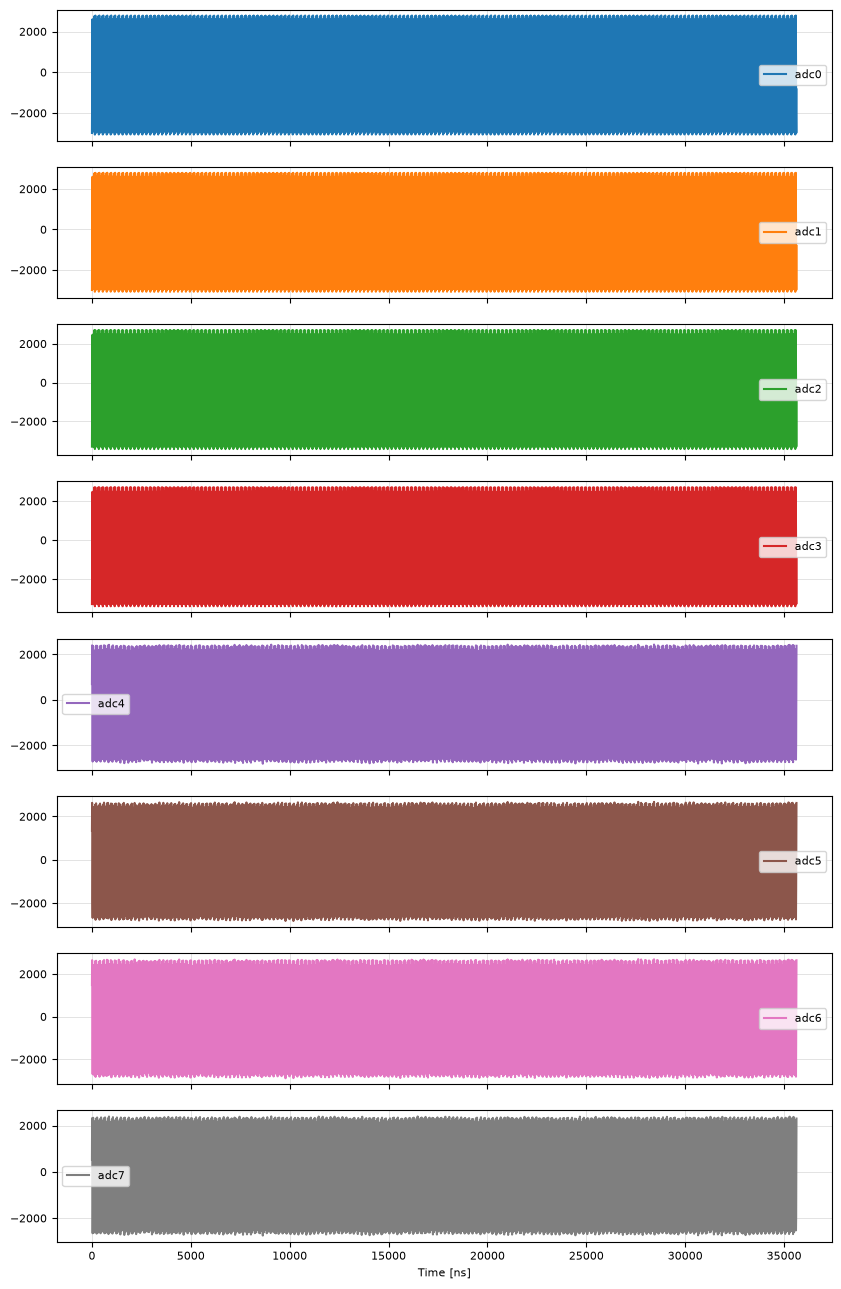

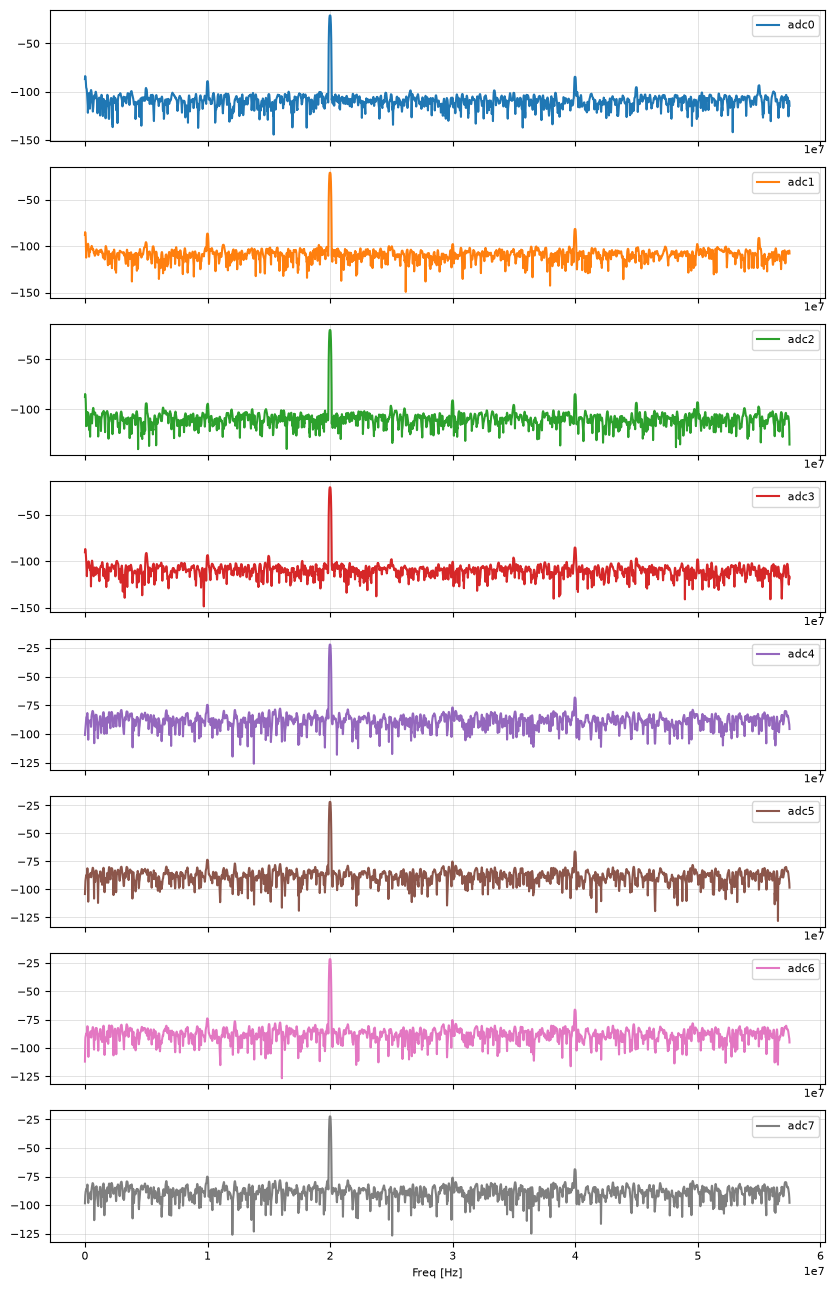

In [7]:
df_sig[cols].loc[:len_ns].plot(subplots=True);
df_psd = llrf.calc_psd_df(df_sig)
df_psd[cols].plot(subplots=True);

for i, col in enumerate(cols):
    print(f'ADC{i} max: {df_psd[col].max():.3f} dBFS at {df_psd[col].idxmax()/1e6:.3f} MHz')

# Get base band IQ waveforms

In [8]:
df_iq = llrf.get_iq_wfms_df()

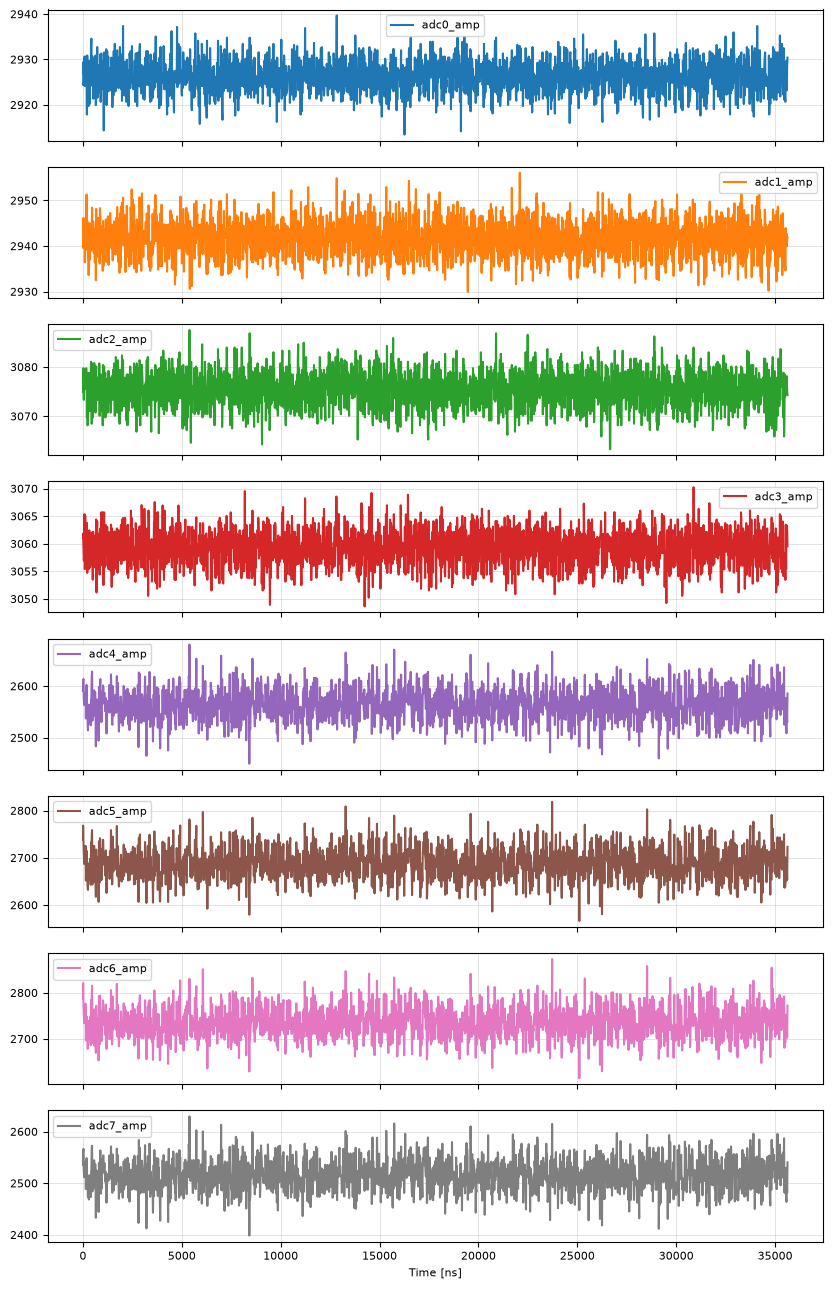

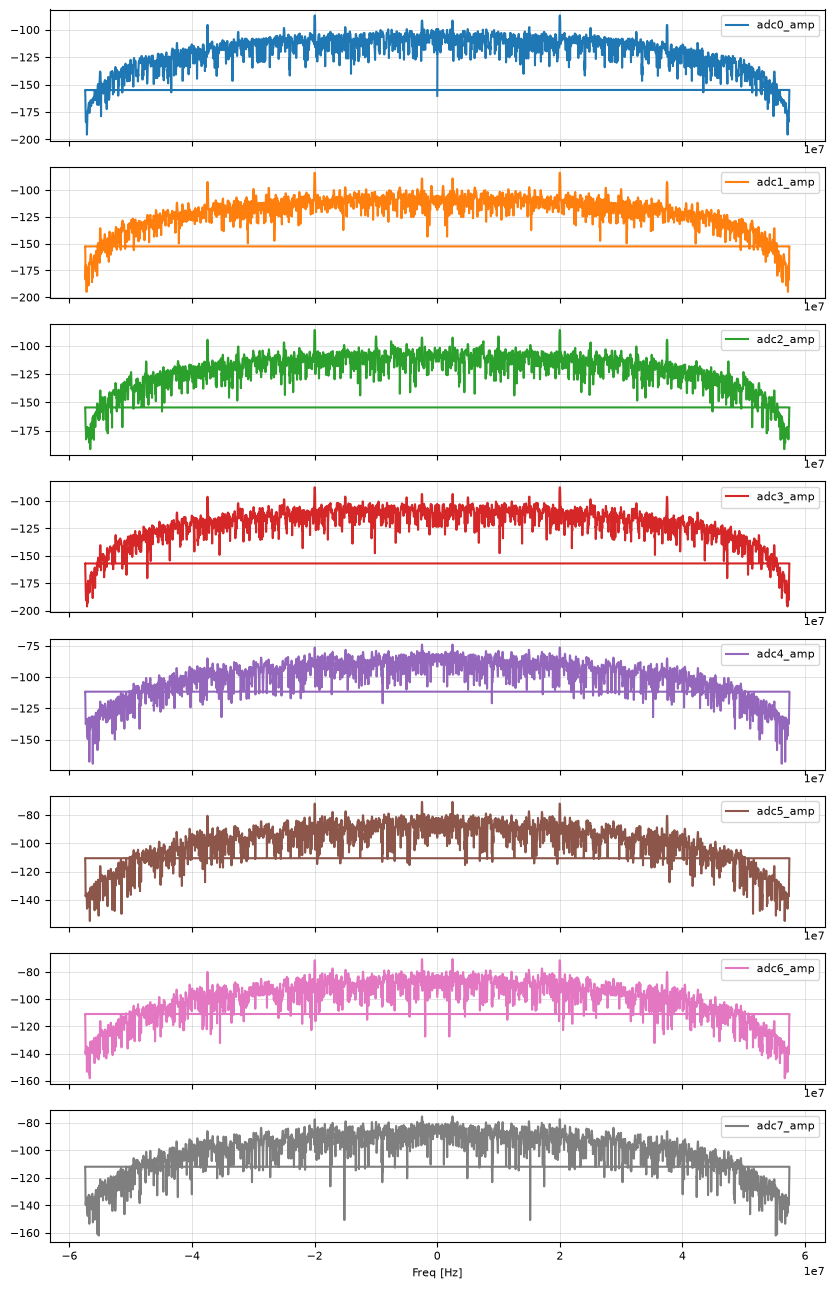

In [9]:
cols_amp = np.array([col + "_amp" for col in cols])
df_iq[cols_amp].loc[:len_ns].plot(subplots=True);

df_iq_psd = llrf.calc_psd_df(df_iq)
df_iq_psd[cols_amp].plot(subplots=True);

# Calculate position data from IQ waveforms

BPM 0 X std: 6846.192
BPM 0 Y std: 5867.028
BPM 1 X std: 7981.384
BPM 1 Y std: 38935.205


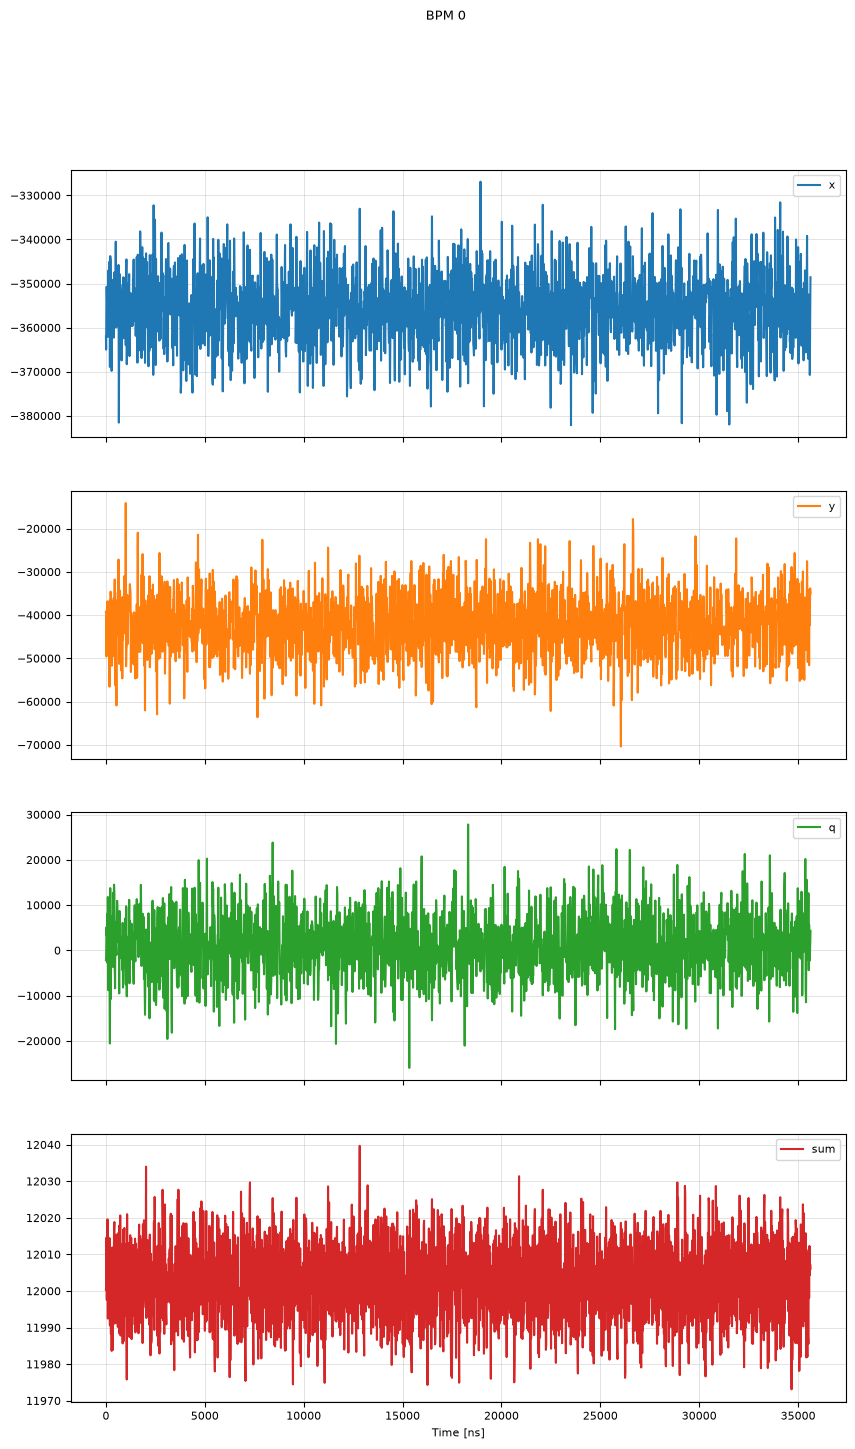

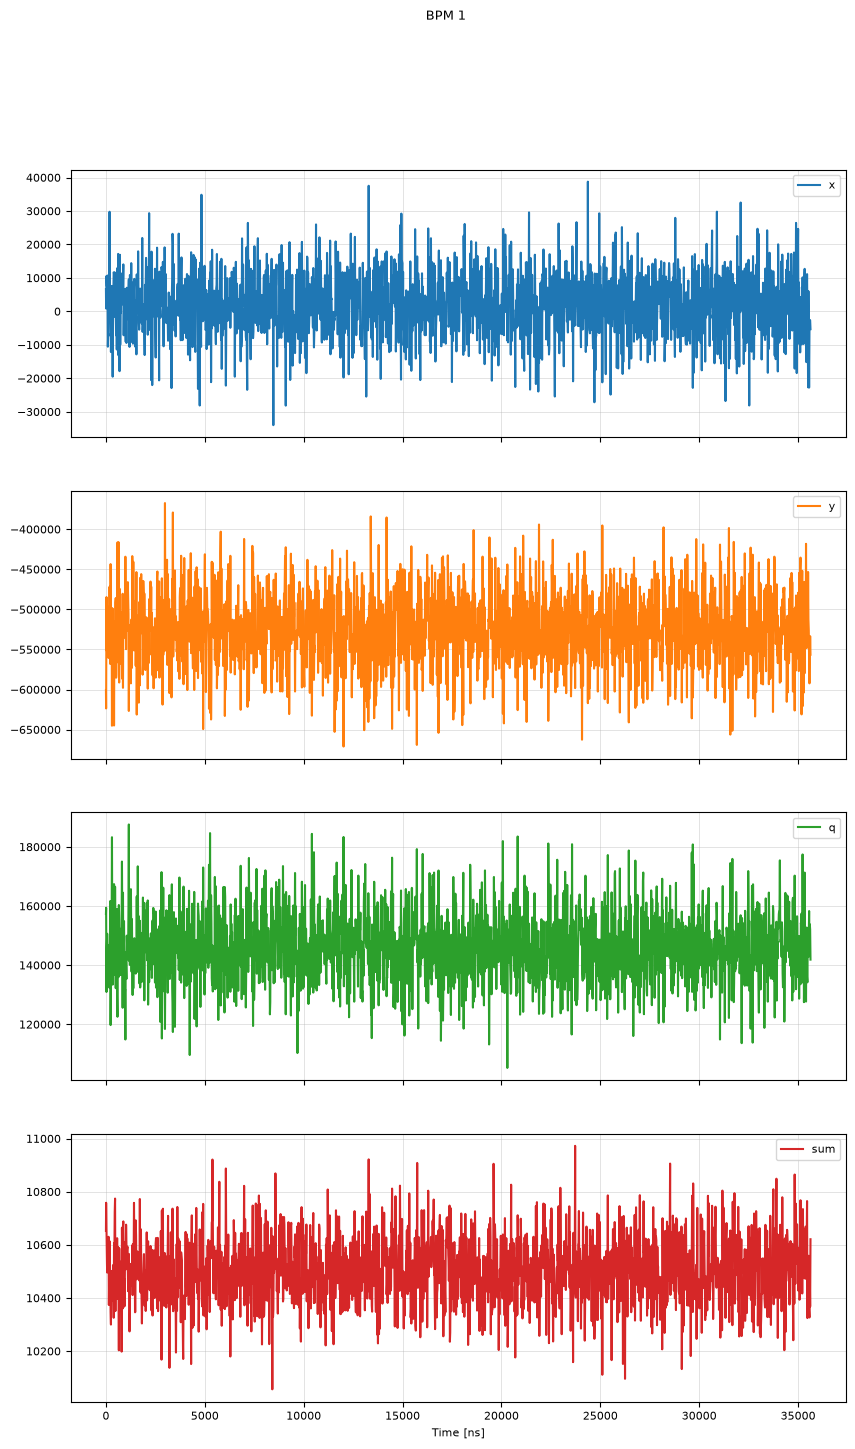

In [10]:
cols_abcd = np.array(["a", "b", "c", "d"])
cols_pos = np.array(["x", "y", "q", "sum"])

Kx = 16e6
Ky = 16e6
Kq = 16e6

bpm_columns = {
    "0": cols_amp[:4],
    "1": cols_amp[4:8],
}

df_pos = {
    bpm: (
        df_iq.loc[:len_ns, channels]
        .rename(columns=dict(zip(channels, cols_abcd)))
        .copy()
    )
    for bpm, channels in bpm_columns.items()
}

for bpm, df in df_pos.items():
    a, b, c, d = (df[col] for col in cols_abcd)

    df["sum"] = a + b + c + d
    df["x"] = Kx * ((a + b) - (c + d)) / df["sum"]
    df["y"] = Ky * ((a + d) - (c + b)) / df["sum"]
    df["q"] = Kq * ((a + c) - (b + d)) / df["sum"]

    df[cols_pos].plot(subplots=True, title=f"BPM {bpm}")

    print(f"BPM {bpm} X std: {df['x'].std(ddof=0):.3f}")
    print(f"BPM {bpm} Y std: {df['y'].std(ddof=0):.3f}")

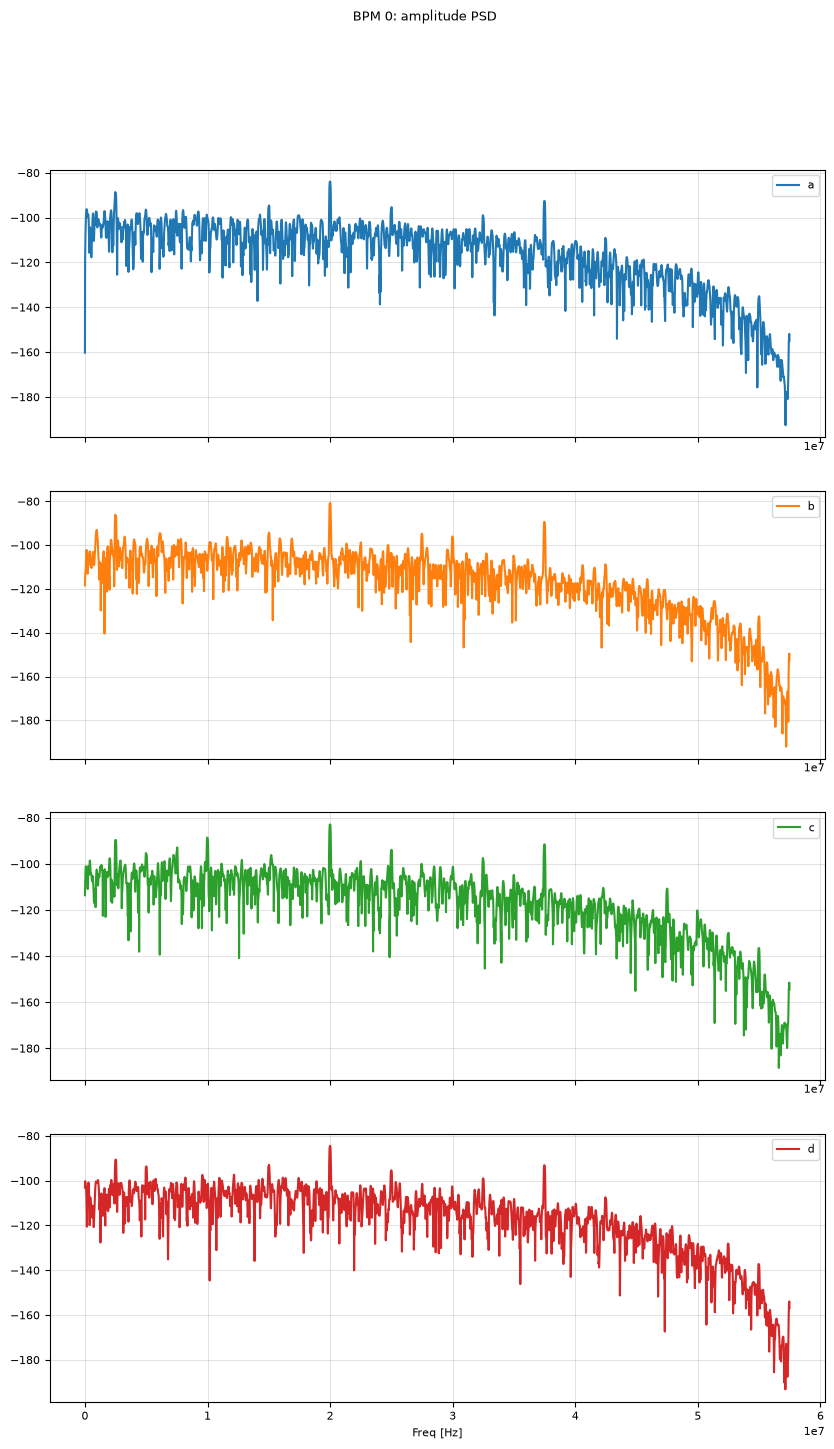

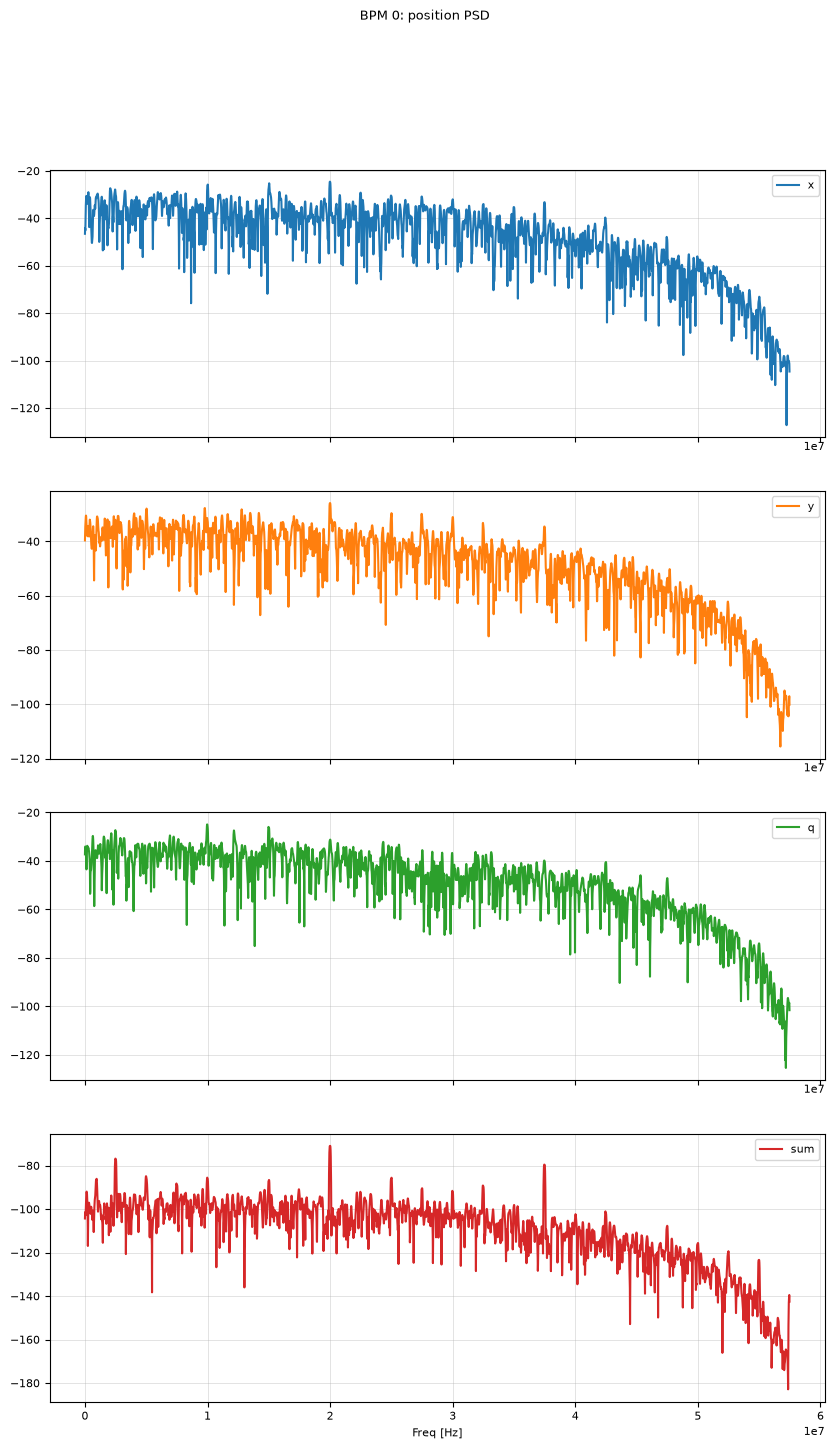

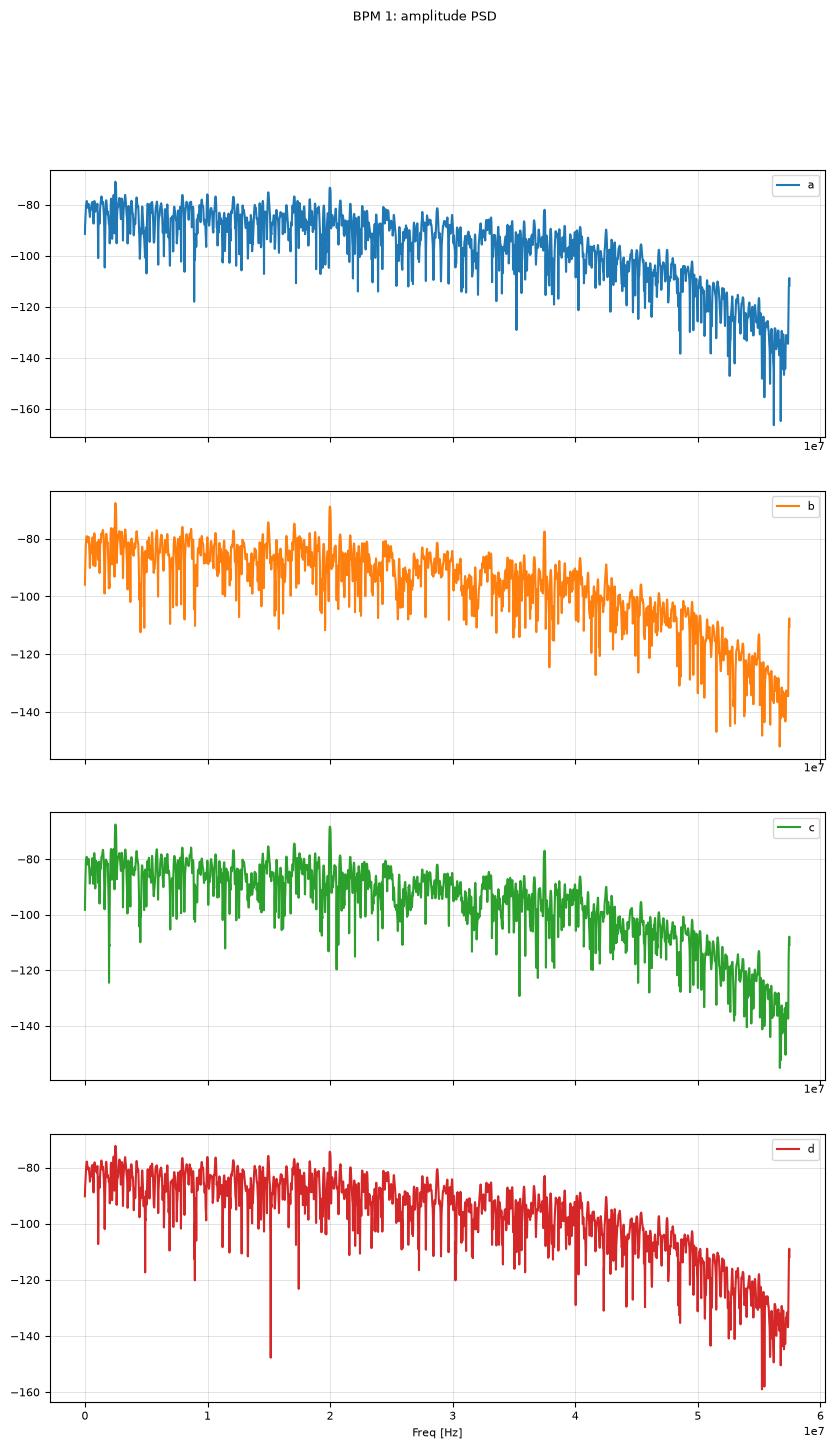

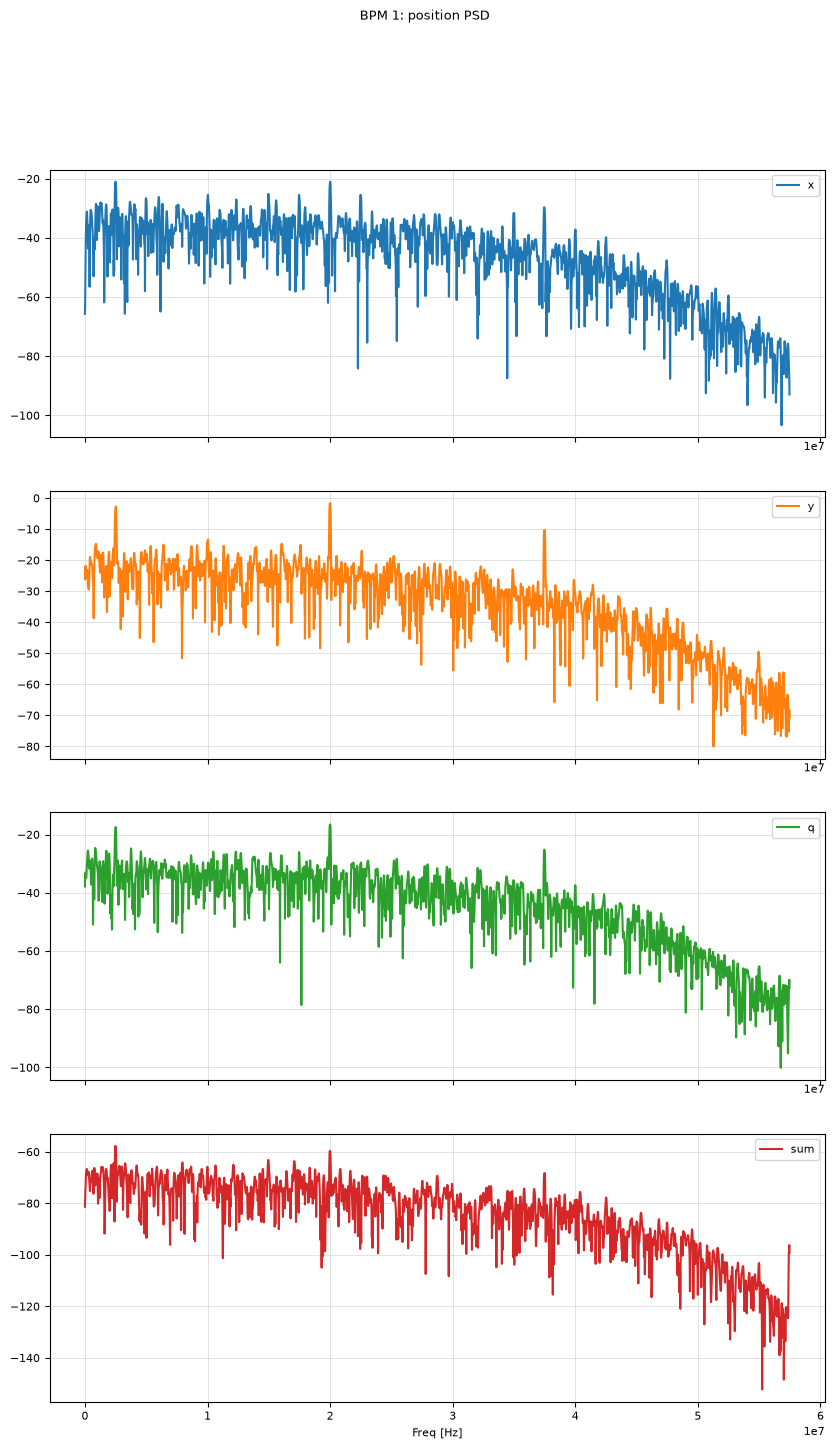

In [11]:
df_pos_psd = {
    bpm: llrf.calc_psd_df(df)
    for bpm, df in df_pos.items()
}

for bpm, df in df_pos_psd.items():
    df[cols_abcd].plot(subplots=True, title=f"BPM {bpm}: amplitude PSD")
    df[cols_pos].plot(subplots=True, title=f"BPM {bpm}: position PSD")

# Get baseband CIC waveforms

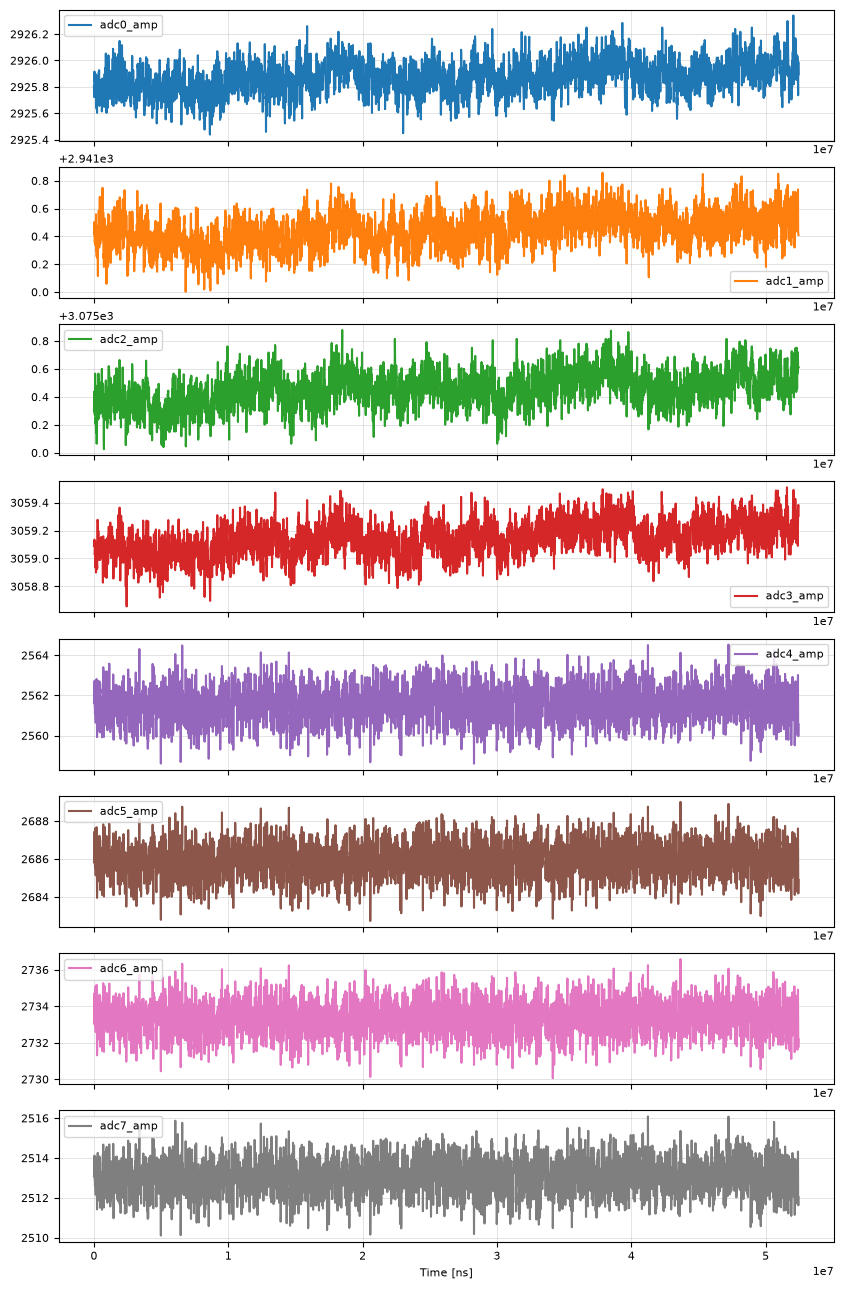

In [13]:
llrf.wave_samp_per = 64
len_ns = 80000000
df_cic = llrf.get_cic_wfm_df()
df_cic[cols_amp].loc[:len_ns].plot(subplots=True);

# Calculate position data from CIC IQ waveforms

BPM 0 X std: 250.384
BPM 0 Y std: 218.107
BPM 1 X std: 263.763
BPM 1 Y std: 1035.845


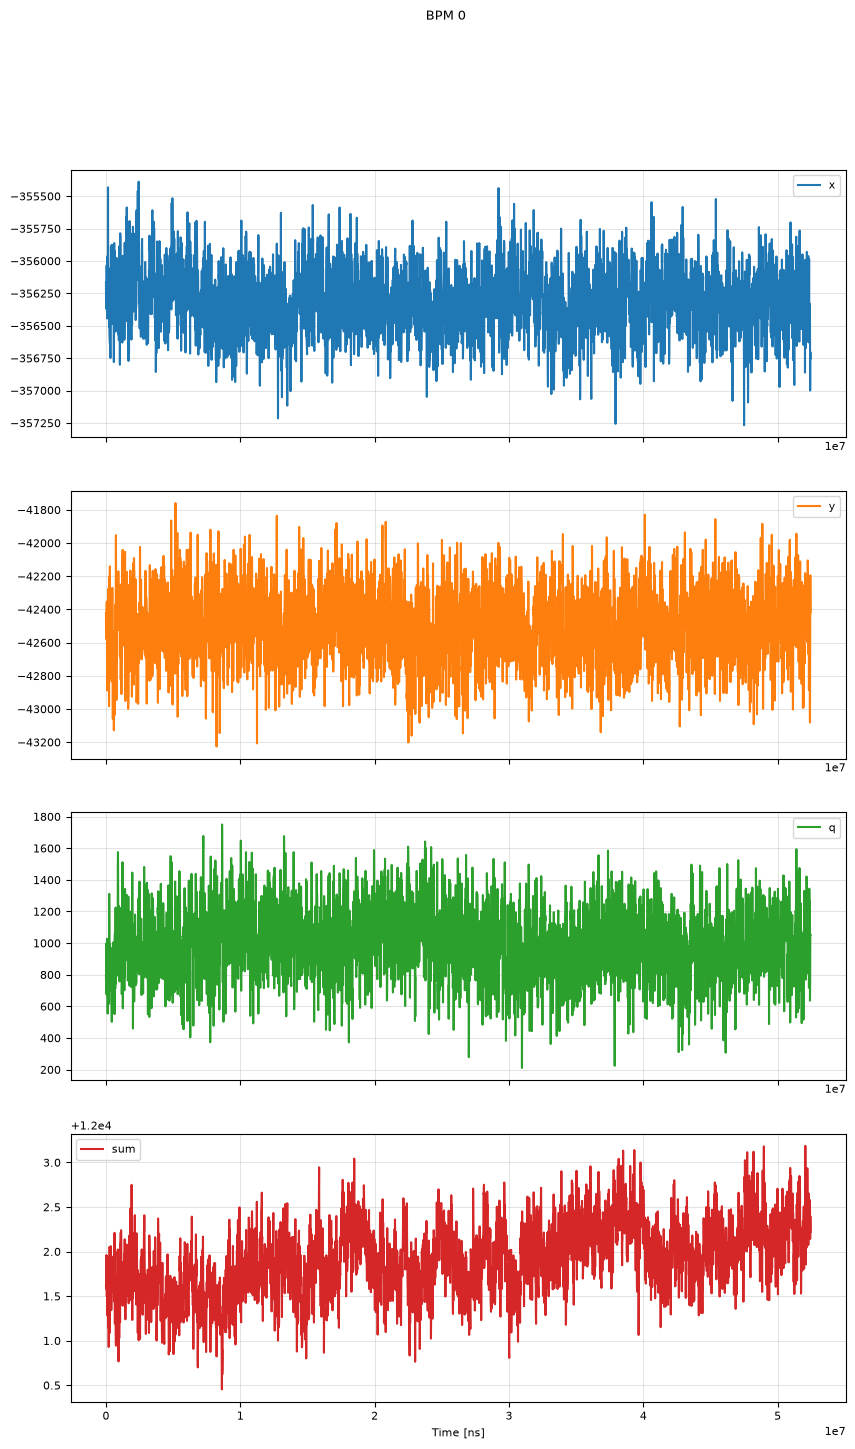

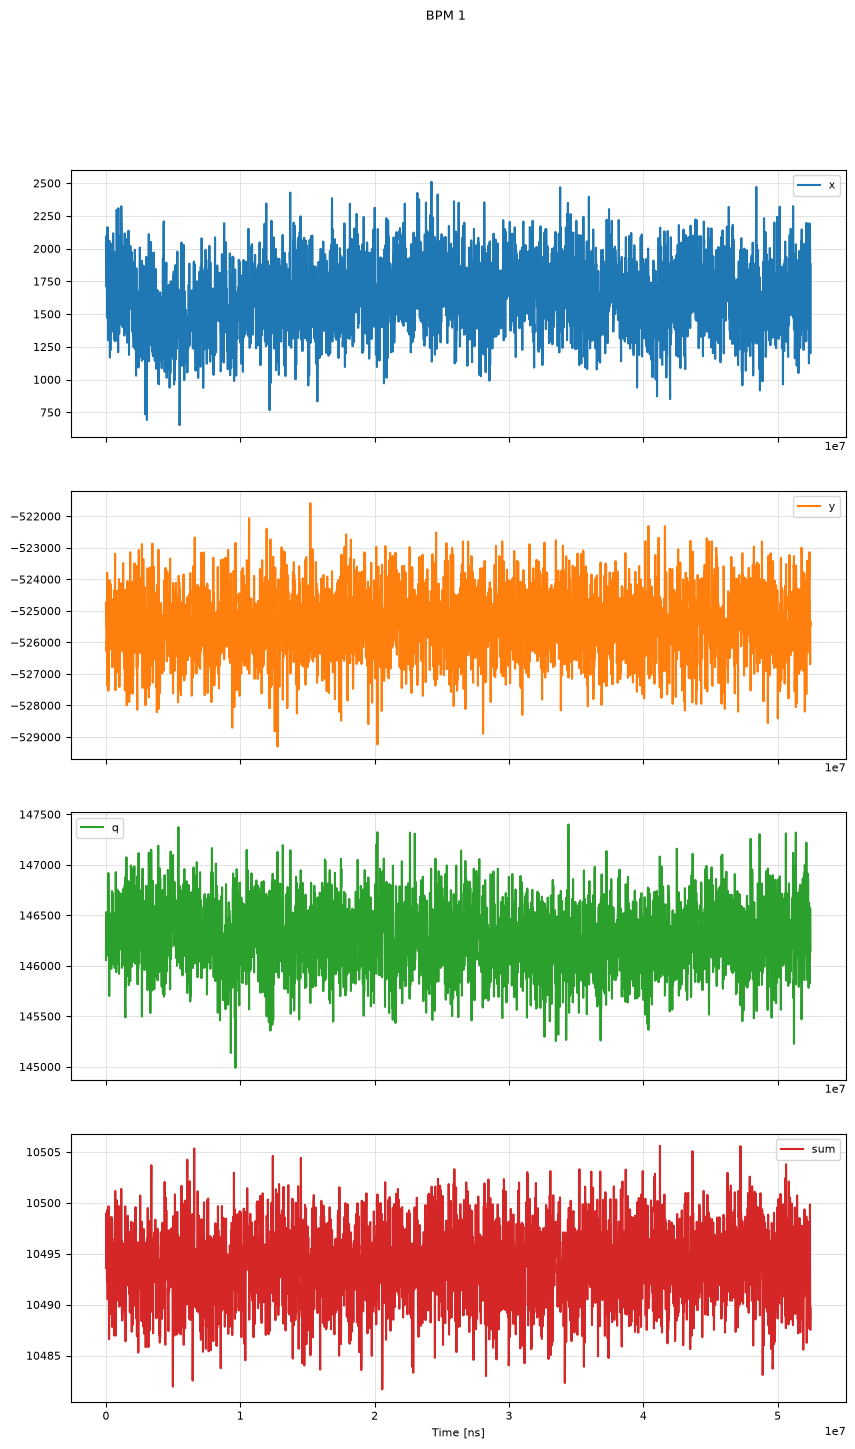

In [14]:
cols_abcd = np.array(["a", "b", "c", "d"])
cols_pos = np.array(["x", "y", "q", "sum"])

Kx = 16e6
Ky = 16e6
Kq = 16e6

bpm_columns = {
    "0": cols_amp[:4],
    "1": cols_amp[4:8],
}

df_cic_pos = {
    bpm: (
        df_cic.loc[:len_ns, channels]
        .rename(columns=dict(zip(channels, cols_abcd)))
        .copy()
    )
    for bpm, channels in bpm_columns.items()
}

for bpm, df in df_cic_pos.items():
    a, b, c, d = (df[col] for col in cols_abcd)

    df["sum"] = a + b + c + d
    df["x"] = Kx * ((a + b) - (c + d)) / df["sum"]
    df["y"] = Ky * ((a + d) - (c + b)) / df["sum"]
    df["q"] = Kq * ((a + c) - (b + d)) / df["sum"]

    df[cols_pos].plot(subplots=True, title=f"BPM {bpm}")

    print(f"BPM {bpm} X std: {df['x'].std(ddof=0):.3f}")
    print(f"BPM {bpm} Y std: {df['y'].std(ddof=0):.3f}")